# Practical 11: Q-Learning (Grid World)

**Aim:** Use Q-Learning on a simple game (Grid World) and study exploration vs exploitation and the optimal policy.

**The game:** a 5 x 5 grid. The robot starts at the top-left and must reach the goal at the bottom-right, avoiding pits.

| Item | Cell | Reward |
|---|---|---|
| Start | (0, 0) | |
| Goal | (4, 4) | +10 (game ends) |
| Pits | (1, 3), (2, 2), (3, 1) | -10 (game ends) |
| Any other step | | -1 (so shorter paths are better) |

Actions: up, down, left, right. There is no dataset: the robot learns by trying.

**Q-learning rule:** `Q(s,a) = Q(s,a) + alpha * (reward + gamma * best Q of next state - Q(s,a))`

**Steps:** 1) Build the game  2) Train  3) Learning curve  4) Optimal policy  5) Exploration vs exploitation

## Step 1: Build the game

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

N = 5
START = (0, 0)
GOAL = (4, 4)
PITS = [(1, 3), (2, 2), (3, 1)]

# actions: 0 = up, 1 = down, 2 = left, 3 = right
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ARROWS = ["↑", "↓", "←", "→"]

def step(state, action):
    # Move the robot and return (new state, reward, game over?)
    row = state[0] + MOVES[action][0]
    col = state[1] + MOVES[action][1]
    if row < 0 or row >= N or col < 0 or col >= N:   # hit a wall: stay where we are
        row, col = state
    new_state = (row, col)
    if new_state == GOAL:
        return new_state, 10, True
    if new_state in PITS:
        return new_state, -10, True
    return new_state, -1, False

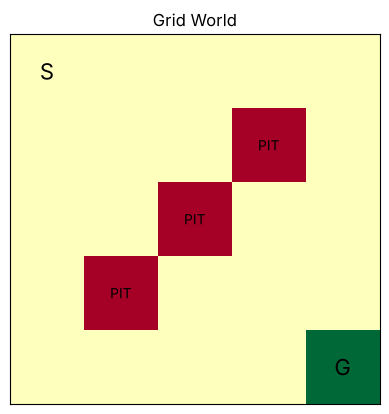

In [2]:
# Draw the grid: green = goal, red = pits
grid = np.zeros((N, N))
grid[GOAL] = 1
for p in PITS:
    grid[p] = -1

plt.imshow(grid, cmap="RdYlGn")
plt.text(0, 0, "S", ha="center", va="center", fontsize=16)
plt.text(4, 4, "G", ha="center", va="center", fontsize=16)
for r, c_ in PITS:
    plt.text(c_, r, "PIT", ha="center", va="center")
plt.xticks([])
plt.yticks([])
plt.title("Grid World")
plt.show()

## Step 2: Train the robot
- **Q-table:** a 5 x 5 x 4 table, the value of each action in each cell. It starts at 0.
- **epsilon-greedy:** with probability `epsilon` take a random action (**explore**), otherwise take the best known action (**exploit**).
- epsilon starts at 1 (all exploring) and decays to 0.05 (mostly exploiting).

In [3]:
def train(episodes=2000, alpha=0.1, gamma=0.95, eps_start=1.0, eps_min=0.05, eps_decay=0.995, seed=0):
    np.random.seed(seed)
    Q = np.zeros((N, N, 4))
    all_rewards = []
    all_eps = []
    epsilon = eps_start

    for episode in range(episodes):
        state = START
        total_reward = 0
        done = False
        steps = 0

        while not done and steps < 100:
            # choose an action: explore or exploit
            if np.random.rand() < epsilon:
                action = np.random.randint(4)
            else:
                action = np.argmax(Q[state])

            new_state, reward, done = step(state, action)

            # Q-learning update
            if done:
                best_next = 0
            else:
                best_next = np.max(Q[new_state])
            Q[state][action] = Q[state][action] + alpha * (reward + gamma * best_next - Q[state][action])

            state = new_state
            total_reward += reward
            steps += 1

        all_rewards.append(total_reward)
        all_eps.append(epsilon)
        epsilon = max(eps_min, epsilon * eps_decay)     # explore less over time

    return Q, all_rewards, all_eps

Q, rewards, eps_values = train()
print("Training finished")

Training finished


## Step 3: Learning curve

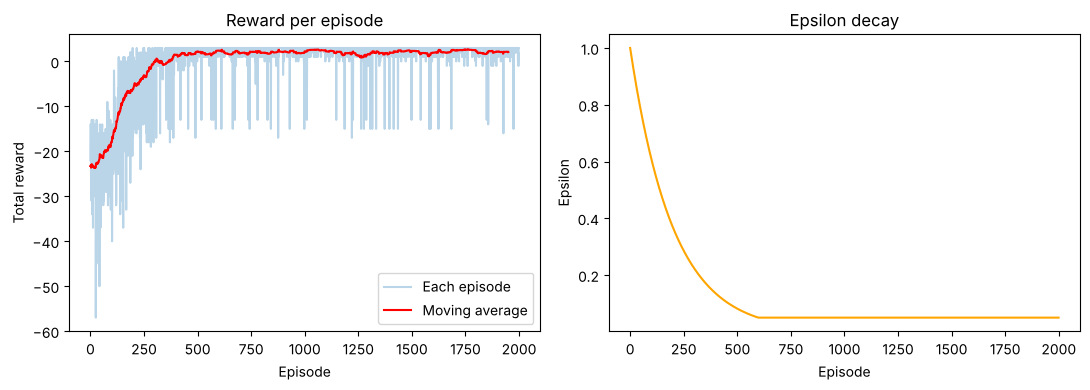

Average reward, first 100 episodes: -22.0
Average reward, last 100 episodes : 2.1


In [4]:
# Smooth the noisy rewards with a moving average of 50 episodes
def smooth(values, window=50):
    return np.convolve(values, np.ones(window) / window, mode="valid")

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(rewards, alpha=0.3, label="Each episode")
plt.plot(smooth(rewards), color="red", label="Moving average")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("Reward per episode")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(eps_values, color="orange")
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.title("Epsilon decay")

plt.tight_layout()
plt.show()

print("Average reward, first 100 episodes:", round(np.mean(rewards[:100]), 1))
print("Average reward, last 100 episodes :", round(np.mean(rewards[-100:]), 1))

**How to read:**
- **Reward per episode:** at the start the robot moves randomly and often falls into a pit (very negative reward). As it learns, the red moving average **rises and levels off**. The best possible reward is **+3** (the shortest safe path has 8 moves: seven steps of -1 and +10 at the goal). It stays a little below 3 because epsilon never reaches 0, so the robot still makes a few random moves.
- **Epsilon decay:** exploration starts at 100% and falls to 5%: first learn about the world, then use what was learned.

## Step 4: The optimal policy

In [5]:
# For each cell, the best action is the one with the highest Q-value
print("Learned policy (G = goal, X = pit):")
for r in range(N):
    line = ""
    for c_ in range(N):
        if (r, c_) == GOAL:
            line += " G "
        elif (r, c_) in PITS:
            line += " X "
        else:
            line += " " + ARROWS[np.argmax(Q[r][c_])] + " "
    print(line)

# Follow the policy from the start
state = START
path = [state]
for _ in range(20):
    state, reward, done = step(state, np.argmax(Q[state]))
    path.append(state)
    if done:
        break
print("\nPath:", path)
print("Reached the goal:", path[-1] == GOAL, "| moves:", len(path) - 1)

Learned policy (G = goal, X = pit):
 →  →  →  →  ↓ 
 →  ↑  ↑  X  ↓ 
 ↓  ←  X  →  ↓ 
 ↓  X  →  →  ↓ 
 →  →  →  →  G 

Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]
Reached the goal: True | moves: 8


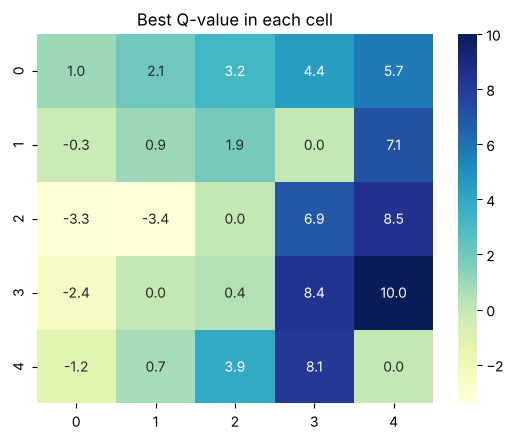

In [6]:
# Heatmap of the best Q-value in each cell: "how good is it to be here?"
values = Q.max(axis=2)
sns.heatmap(values, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Best Q-value in each cell")
plt.show()

**How to read:** the arrows are the **optimal policy**: in each cell, the action with the highest Q-value. Following them from the start leads to the goal while avoiding the pits. Cells the robot rarely visits can have odd-looking arrows. In the heatmap, values are **highest next to the goal** and get lower further away (each step costs -1 and future rewards are discounted); cells next to a pit are lower.

## Step 5: Exploration vs exploitation
We train three robots that differ only in how they explore, and average each over 3 runs:
- **epsilon = 0.05 (fixed):** almost always exploits.
- **epsilon = 0.5 (fixed):** explores half of the time.
- **decaying epsilon** (1.0 to 0.05): explores first, exploits later.

Fixed epsilon = 0.05 | average reward in the last 300 episodes: 2.2


Fixed epsilon = 0.5 | average reward in the last 300 episodes: -9.9


Decaying epsilon | average reward in the last 300 episodes: 2.3


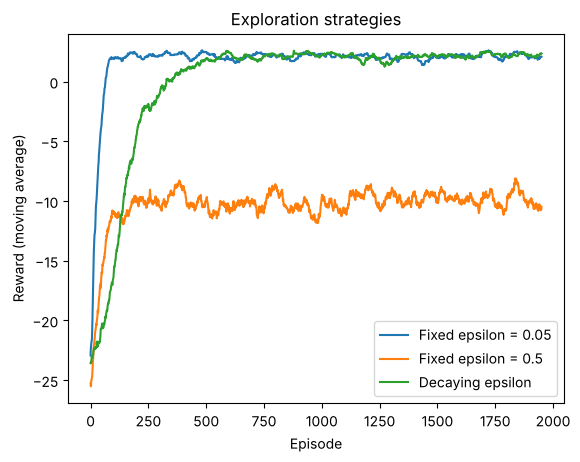

In [7]:
strategies = {
    "Fixed epsilon = 0.05": dict(eps_start=0.05, eps_min=0.05, eps_decay=1.0),
    "Fixed epsilon = 0.5": dict(eps_start=0.5, eps_min=0.5, eps_decay=1.0),
    "Decaying epsilon": dict(eps_start=1.0, eps_min=0.05, eps_decay=0.995),
}

for name, settings in strategies.items():
    runs = []
    for seed in range(3):
        _, r, _ = train(seed=seed, **settings)
        runs.append(r)
    average = np.mean(runs, axis=0)
    plt.plot(smooth(average), label=name)
    print(name, "| average reward in the last 300 episodes:", round(np.mean(average[-300:]), 1))

plt.xlabel("Episode")
plt.ylabel("Reward (moving average)")
plt.title("Exploration strategies")
plt.legend()
plt.show()

**How to read:**
- **Fixed epsilon = 0.5:** its reward stays low (it keeps making random moves, often into pits) even though it has learned the right Q-values. Too much exploration hurts the reward you actually collect.
- **Fixed epsilon = 0.05:** good reward from early on on this small grid.
- **Decaying epsilon:** worst at the very start (100% random) but ends at the same good level. It is the usual best choice because it explores first and exploits later. On a small, easy grid like this one a small fixed epsilon works just as well; the decaying strategy matters more in bigger, harder problems.

## Conclusion
The robot learned a policy that goes from the start to the goal in 8 moves while avoiding all pits; its reward improved from strongly negative (random moves) to close to the best possible +3. Epsilon-greedy balances exploration (trying new actions) and exploitation (using what is known): too much exploring lowers the reward collected, too little can miss better paths. A decaying epsilon is a good compromise.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is reinforcement learning?**
A learning paradigm where an agent interacts with an environment, takes actions, receives rewards, and learns a policy that maximises cumulative reward.

**Q2. Define agent, environment, state, action, reward and policy.**
Agent: the learner. Environment: the world it acts in. State: the current situation. Action: a choice the agent makes. Reward: scalar feedback. Policy: a mapping from states to actions.

**Q3. What is Q-Learning?**
A model-free, off-policy, value-based RL algorithm that learns the action-value function $Q(s,a)$: the expected total future reward for taking action a in state s and then acting optimally.

**Q4. Explain the Q-learning update rule.**
New Q = old Q + $\alpha$ × (reward + $\gamma$ × best next Q − old Q). The bracket is the temporal-difference (TD) error: the gap between the target and the current estimate.

**Q5. What is the learning rate α?**
How much new information overrides old. 0 means no learning; 1 means only the latest experience is used. Typical value about 0.1.

**Q6. What is the discount factor γ?**
Controls how much future rewards matter. Near 0: short-sighted; near 1: far-sighted. Typical 0.9 to 0.99.

**Q7. What is exploration vs exploitation?**
Exploration: trying new actions to discover better rewards. Exploitation: using current knowledge to pick the best-known action. Both are needed.

**Q8. What is epsilon-greedy?**
With probability ε choose a random action (explore); with probability 1 − ε choose the action with the highest Q (exploit). ε is usually decayed over time.

**Q9. Why decay epsilon?**
Early on, the Q-table is uninformed, so explore a lot. Later the policy is good, so exploit more and earn higher rewards.

**Q10. What does "model-free" mean?**
The agent does not know or learn the environment's transition probabilities or reward function; it learns directly from experience.

**Q11. What does "off-policy" mean?**
Q-learning updates using the greedy best next action (max Q), regardless of which action the behaviour policy actually takes. SARSA is on-policy: it uses the action actually taken.

**Q12. Q-Learning vs SARSA?**
Q-learning's target uses $\max_{a'}Q(s',a')$, so it learns the optimal policy and is more optimistic (it takes risks near pits). SARSA uses the $Q(s',a')$ of the action actually taken, so it learns a safer policy that accounts for its own exploration.

**Q13. What is the Q-table?**
A table with one row per state and one column per action, storing Q-values.

**Q14. What is the optimal policy?**
The policy that maximises expected cumulative reward from every state; derived as $\pi^*(s)=\arg\max_a Q(s,a)$.

**Q15. What is the Bellman equation?**
$Q^*(s,a)=E[\,r+\gamma\max_{a'}Q^*(s',a')\,]$: the value of a state-action equals the immediate reward plus the discounted best value of the next state. Q-learning is a sample-based way to solve it.

**Q16. What are the limitations of tabular Q-learning?**
It does not scale to large or continuous state spaces (the table explodes). Solution: function approximation such as Deep Q-Networks (DQN).

**Q17. What is an episode?**
One complete run from the start state until a terminal state (goal or pit) or a step limit.

**Q18. What is a Markov Decision Process (MDP)?**
The mathematical framework for RL: states, actions, transition probabilities, rewards and a discount factor; the next state depends only on the current state and action (Markov property).

**Q19. Does Q-learning always converge?**
In the tabular case, yes to the optimal Q-values, provided every state-action pair is visited infinitely often and the learning rate decays appropriately.

**Q20. Why is the step reward −1?**
It penalises long paths, so the agent prefers the shortest route to the goal instead of wandering.

**Q21. Why are pits given −10 and the goal +10?**
Terminal rewards signal good and bad outcomes. Falling in a pit ends the episode with a big penalty, so the agent learns to avoid it; reaching the goal gives a big reward that propagates backwards through Q-values.

**Q22. What is the difference between reward and value (Q)?**
Reward is the immediate feedback for one step. Value/Q is the expected sum of all future (discounted) rewards.

**Q23. What is the credit assignment problem?**
Deciding which earlier actions deserve credit for a delayed reward. Q-learning solves it by propagating value backwards through the TD updates.

**Q24. How does RL differ from supervised learning?**
There are no labelled examples; feedback is a delayed, evaluative reward signal, and the agent's actions affect the data it sees later.

**Q25. What is a terminal state?**
A state where the episode ends (goal or pit); its future value is 0, so the update there uses only the immediate reward.

**Q26. Real-world uses of RL?**
Games (Go, Atari), robotics, recommendation systems, resource scheduling, autonomous driving, and tuning language models from human feedback.

## B. Questions about the graphs

**G1. What does the learning curve (reward vs episode) show?**
Learning progress. It starts low and noisy (exploration, many pit falls), rises as Q-values improve, and flattens near the maximum when the policy has converged.

**G2. Why is the curve noisy even at the end?**
Because epsilon never reaches 0 (minimum 0.05), the agent still takes occasional random actions. A moving average smooths it.

**G3. Why does the reward level off around +3 and not +10?**
The goal gives +10 but each of the 7 earlier steps costs −1, so the best possible return is 10 − 7 = +3 on the shortest path.

**G4. How do you read the policy grid?**
Each cell shows the best action (arrow) from that state, i.e. argmax Q(s, a). Following the arrows from the start should reach the goal while avoiding pits.

**G5. What does the value heatmap show?**
The maximum Q-value in each state. Values are highest next to the goal and fall with distance (discounting); cells next to pits are lower.

**G6. What does the epsilon decay plot show?**
Epsilon falling from 1.0 to 0.05: mostly exploration at first, mostly exploitation at the end.

**G7. Compare the curves for different epsilon strategies.**
A very high fixed epsilon (0.5) learns a correct Q-table but keeps getting low rewards because it keeps acting randomly (often into pits). A small fixed epsilon (0.05) and a decaying epsilon both end near the best reward; the decaying one starts worst because it begins with 100% random moves. Decaying epsilon is the usual choice: explore first, exploit later.

## C. Code questions

**C1. What does `Q[s][a] += alpha * (r + gamma * Q[ns].max() - Q[s][a])` do?**
The Q-learning (Bellman/TD) update for the state-action just taken.

**C2. Why is the next-state value set to 0 when `done`?**
A terminal state has no future, so the target is just the immediate reward.

**C4. Why `max_steps = 100`?**
To stop endless episodes if the agent wanders without reaching a terminal state.

**C5. Why average over several random seeds when comparing strategies?**
RL results are noisy because of random exploration; averaging gives a fairer comparison.